# AVAX LONG — mean reversion ở dải Bollinger (Bollinger dài hạn, RSI ngắn hạn), train full grid trên GPU

Notebook này dùng `train_full_grid_gpu.py` cùng thư mục (logic chung ở `reference/multi_position/multi_position_engine.py`). Sửa **ô Cấu hình**, rồi chọn **Run All**. Kết quả lưu thành CSV cạnh notebook.

**Ý tưởng:** Bollinger là chỉ báo **dài hạn** (`boll_window` 48–672 nến = 12 giờ → 7 ngày ở 15min), RSI là chỉ báo **ngắn hạn** (`rsi_window` 2–14). Khi giá ra ngoài dải và RSI ở vùng cực, vào lệnh **ngược chiều** với nhịp vừa xảy ra.

**Vào lệnh ở close của nến `i`** — cột `entry_mode`:
- `1` — giá vượt ra ngoài dải: `close[i-1] > lower[i] > close[i]` (đóng cửa vượt xuống dưới dải dưới) **và** `RSI[i] < rsi_threshold`
- `2` — giá quay lại trong dải: `close[i-1] < lower[i] < close[i]` (quay lại trong dải) **và** `RSI[i] < rsi_threshold`

**Risk** = `sl_multiplier × (upper[i] − lower[i])` (độ rộng dải); stop = entry − risk; TP = entry + `tp_sl_ratio` × risk, hoặc dải giữa khi `tp_sl_ratio = -1` (dải giữa = SMA tại nến vào, cố định như lệnh limit; chạm TP ⇒ R = khoảng cách tới dải giữa ÷ risk). Timeout `MAX_HOLDING_BARS` nến; phí vào lệnh `0.001 / sl_ratio` (bỏ lệnh nếu > 0.2R); phí giữ lệnh mỗi 8 giờ (`FEE_BARS = None` ⇒ 32 ở 15min); một lệnh mỗi lúc.

Grid search trên toàn khoảng train là **in-sample**; đánh giá ngoài mẫu bằng `reference/walk_forward_multi_asset.py --folder long_bollinger+RSI+fade` (đọc grid và `SCORE_FORMULA` từ ô Cấu hình này).

In [1]:
# CẤU HÌNH — sửa ô này trước khi chạy
TIMEFRAME = "15min"                 # ví dụ "5min", "15min", "1h", "4h"
START_DATE = "2024-07-01"          # ngày bắt đầu, bao gồm ngày này
END_DATE = "2026-01-14"            # ngày kết thúc, bao gồm ngày này
DATA_CSV = None                     # None = reference/data/avaxusdt_futures_5min.csv
SCRIPT_PATH = None                  # None = tự tìm train_full_grid_gpu.py

SCORE_FORMULA = "r_martin_monthly"
# Sửa trực tiếp các danh sách dưới đây để đổi grid. Số bộ tham số là tích số giá trị mỗi danh sách.
# tp_sl_ratio = -1 nghĩa là chốt lời ở dải giữa; entry_mode 1 = vượt ra ngoài dải, 2 = quay lại trong dải.
SEARCH_SPACES = {
    "boll_window": [48, 96, 192, 288, 480, 672],
    "boll_window_dev": [1.8, 2.0, 2.2, 2.5, 3.0],
    "rsi_window": [2, 3, 4, 5, 7, 9, 14],
    "rsi_threshold": [5, 10, 15, 20, 25, 30, 35],
    "sl_multiplier": [0.25, 0.375, 0.5, 0.75, 1.0],
    "tp_sl_ratio": [0.5, 0.75, 1.0, 1.5, 2.0, -1],
    "entry_mode": [1, 2],
}
LIMIT = None                         # None = toàn bộ bộ tham số; số nguyên để chạy thử
MAX_HOLDING_BARS = 288             # số nến tối đa giữ lệnh theo TIMEFRAME
FEE_BARS = None                    # None = 8 giờ mỗi lần phí (32 ở 15min)
VERIFY_SAMPLES = 0                  # 0 = bỏ qua so với CPU; ví dụ 8 = kiểm tra 8 bộ
MIN_TRADES = 40                     # bảng xếp hạng chỉ giữ bộ có ít nhất số lệnh này
OUTPUT_CSV = None                   # None = CSV theo timeframe, cạnh notebook

In [2]:
# Nạp script cùng thư mục (cũng hoạt động khi kernel bắt đầu ở thư mục khác trong repo)
from pathlib import Path
import importlib.util
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SIDE_FOLDER = "long_bollinger+RSI+fade"
if SCRIPT_PATH is None:
    candidates = []
    for parent in (Path.cwd(), *Path.cwd().parents):
        if parent.name == SIDE_FOLDER:
            candidates.append(parent / "train_full_grid_gpu.py")
        candidates.append(parent / "reference" / SIDE_FOLDER / "train_full_grid_gpu.py")
    script_path = next((path.resolve() for path in candidates if path.is_file()), None)
    if script_path is None:
        raise FileNotFoundError("Không tìm thấy train_full_grid_gpu.py; hãy đặt SCRIPT_PATH ở ô Cấu hình")
else:
    script_path = Path(SCRIPT_PATH).expanduser().resolve()
if not script_path.is_file():
    raise FileNotFoundError(script_path)

spec = importlib.util.spec_from_file_location("avax_long_bollinger_RSI_fade", script_path)
strategy = importlib.util.module_from_spec(spec)
spec.loader.exec_module(strategy)
csv_path = Path(DATA_CSV).expanduser().resolve() if DATA_CSV else strategy.DEFAULT_CSV
if not csv_path.is_file():
    raise FileNotFoundError(csv_path)
print("CSV:", csv_path)
print("Đã nạp:", script_path)
print("Phí giữ lệnh: mỗi", strategy.resolve_fee_bars(TIMEFRAME, FEE_BARS), "nến")

CSV: C:\Users\Legion\Desktop\TradingProject\reference\data\avaxusdt_futures_5min.csv
Đã nạp: C:\Users\Legion\Desktop\TradingProject\reference\long_bollinger+RSI+fade\train_full_grid_gpu.py
Phí giữ lệnh: mỗi 32.0 nến


In [3]:
# Đọc dữ liệu, resample và tạo grid
strategy.timeframe_nanos(TIMEFRAME)
start_date, end_date = START_DATE, END_DATE
expected_keys = set(strategy.SEARCH_SPACE)
space = SEARCH_SPACES
if set(space) != expected_keys:
    raise ValueError(f"SEARCH_SPACES cần đúng các khóa: {sorted(expected_keys)}")
for name, values in space.items():
    if not isinstance(values, (list, tuple)) or not values:
        raise ValueError(f"{name} phải là danh sách có ít nhất một giá trị")
space = {name: list(values) for name, values in space.items()}

bars = strategy.load_bars(csv_path, TIMEFRAME, start_date, end_date)
combinations = itertools.product(*(space[name] for name in space))
if LIMIT is not None:
    combinations = itertools.islice(combinations, LIMIT)
grid = pd.DataFrame(combinations, columns=list(space))
print(f"Dữ liệu: {len(bars):,} nến; {bars['timestamp'].iloc[0]} → {bars['timestamp'].iloc[-1]}")
print(f"Grid: {len(grid):,} bộ tham số")
display(grid.head())

Dữ liệu: 54,006 nến; 2024-07-01 00:00:00 → 2026-01-14 13:15:00
Grid: 88,200 bộ tham số


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio,entry_mode
0,48,1.8,2,5,0.25,0.50,1
1,48,1.8,2,5,0.25,0.50,2
2,48,1.8,2,5,0.25,0.75,1
3,48,1.8,2,5,0.25,0.75,2
4,48,1.8,2,5,0.25,1.00,1


In [4]:
# Chạy toàn bộ grid trên GPU
result, timing = strategy.run_gpu_grid(
    bars, grid, TIMEFRAME,
    max_holding_bars=MAX_HOLDING_BARS,
    fee_bars=FEE_BARS,
    score_formula=SCORE_FORMULA,
)
print("Thời gian:", timing)
print(f"Đã tính {len(result):,} bộ tham số")

C:\Users\Legion\anaconda3\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))


Thời gian: {'indicators_and_transfer_s': 1.2170735000108834, 'holding_fee_bars': 32.0, 'total_gpu_s': 3.7544199999974808}
Đã tính 88,200 bộ tham số


In [5]:
# TÍNH LẠI SCORE — chạy lại riêng ô này sau khi đổi SCORE_FORMULA
result = strategy.score_result(result, SCORE_FORMULA)
print("Score:", SCORE_FORMULA)

Score: r_martin_monthly


In [6]:
# Kiểm tra CPU (tùy chọn): đối chiếu mẫu với replay float64
if VERIFY_SAMPLES:
    strategy.verify_samples(bars, result, VERIFY_SAMPLES, MAX_HOLDING_BARS, FEE_BARS, TIMEFRAME)

In [7]:
# Lưu kết quả và xem các bộ tham số đứng đầu
output_path = (Path(OUTPUT_CSV).expanduser().resolve() if OUTPUT_CSV
               else script_path.with_name(f"full_gpu_grid_results_{TIMEFRAME}_fp32.csv"))
output_path.parent.mkdir(parents=True, exist_ok=True)
result.to_csv(output_path, index=False)

ranked = result.loc[(result["number_of_trade"] >= MIN_TRADES) & result["score"].notna()].sort_values("score", ascending=False)

print("Đã lưu:", output_path)
print(f"Bộ có score hợp lệ và ≥ {MIN_TRADES} lệnh: {len(ranked):,}/{len(result):,}")
display(ranked.head(20))

Đã lưu: C:\Users\Legion\Desktop\TradingProject\reference\long_bollinger+RSI+fade\full_gpu_grid_results_15min_fp32.csv
Bộ có score hợp lệ và ≥ 40 lệnh: 33,872/88,200


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio,entry_mode,performance,max_dd,avg_dd,...,ulcer_r,r_martin_monthly,r_sharpe_monthly,mtm_max_dd,avg_concurrent,number_of_trade,max_concurrent,skipped_entries,score,score_formula
15513,96,1.8,3,35,0.500,2.00,2,18.884693,3.39,0.93,...,1.423121,0.717969,0.421683,3.875987,0.085713,50,1,8,0.717969,r_martin_monthly
46141,288,1.8,7,35,0.250,0.50,2,9.723038,2.25,0.36,...,0.883143,0.595673,0.568863,2.503708,0.011925,46,1,5,0.595673,r_martin_monthly
17482,96,1.8,14,25,0.375,-1.00,1,15.949208,3.25,0.97,...,1.475340,0.584904,0.373874,4.043869,0.041495,49,1,6,0.584904,r_martin_monthly
33583,192,2.0,4,35,0.750,1.50,2,11.820403,2.76,0.79,...,1.149790,0.556226,0.380561,3.736206,0.114006,41,1,7,0.556226,r_martin_monthly
46143,288,1.8,7,35,0.250,0.75,2,10.670145,2.51,0.54,...,1.108113,0.520983,0.447768,2.991526,0.018850,46,1,5,0.520983,r_martin_monthly
35263,192,2.0,14,35,0.750,1.50,2,10.854558,2.39,0.75,...,1.163995,0.504543,0.347379,3.808174,0.126616,43,1,18,0.504543,r_martin_monthly
15511,96,1.8,3,35,0.500,1.50,2,12.980920,3.88,0.96,...,1.403010,0.500590,0.351006,4.371408,0.074788,50,1,8,0.500590,r_martin_monthly
33581,192,2.0,4,35,0.750,1.00,2,9.007738,2.39,0.69,...,1.019118,0.478221,0.335300,3.058335,0.084065,42,1,6,0.478221,r_martin_monthly
397,48,1.8,2,35,0.750,0.50,2,8.274572,3.10,0.71,...,0.956236,0.468186,0.380999,3.363230,0.024479,62,1,2,0.468186,r_martin_monthly
34423,192,2.0,7,35,0.750,1.50,2,12.122776,3.10,0.96,...,1.439135,0.455762,0.338204,4.216047,0.156853,55,1,16,0.455762,r_martin_monthly


In [8]:
# So sánh theo từng chiều tham số: trung vị toàn grid (ít nhiễu hơn bộ "tốt nhất")
view = result.assign(tp_kind=np.where(result["tp_sl_ratio"] < 0, "dải giữa", "R cố định"))


def family(frame):
    return pd.Series({
        "số bộ": len(frame),
        "lệnh (trung vị)": frame["number_of_trade"].median(),
        f"% bộ ≥ {MIN_TRADES} lệnh": (frame["number_of_trade"] >= MIN_TRADES).mean(),
        "R/tháng (trung vị)": frame["r_per_month"].median(),
        "% bộ có lãi": (frame["performance"] > 0).mean(),
        "max DD (trung vị)": frame["max_dd"].median(),
    })


for columns in (["entry_mode"], ["tp_kind"], ["entry_mode", "tp_kind"], ["rsi_window"], ["boll_window"], ["rsi_threshold"]):
    print("Theo", ", ".join(columns))
    display(view.groupby(columns).apply(family).round(3))

Theo entry_mode


C:\Users\Legion\AppData\Local\Temp\ipykernel_20568\636225071.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(view.groupby(columns).apply(family).round(3))


,số bộ,lệnh (trung vị),% bộ ≥ 40 lệnh,R/tháng (trung vị),% bộ có lãi,max DD (trung vị)
entry_mode,,,,,,
1,44100.0,69.0,0.683,-0.605,0.070,14.54
2,44100.0,3.0,0.085,0.000,0.251,1.03


Theo tp_kind


C:\Users\Legion\AppData\Local\Temp\ipykernel_20568\636225071.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(view.groupby(columns).apply(family).round(3))


,số bộ,lệnh (trung vị),% bộ ≥ 40 lệnh,R/tháng (trung vị),% bộ có lãi,max DD (trung vị)
tp_kind,,,,,,
R cố định,73500.0,18.0,0.384,-0.101,0.159,3.86
dải giữa,14700.0,18.0,0.384,-0.099,0.167,3.92


... (8 outputs left out)

,số bộ,lệnh (trung vị),% bộ ≥ 40 lệnh,R/tháng (trung vị),% bộ có lãi,max DD (trung vị)
boll_window,,,,,,
48,14700.0,55.0,0.539,-0.298,0.140,9.740
96,14700.0,35.0,0.481,-0.226,0.156,7.750
192,14700.0,22.0,0.427,-0.142,0.168,4.700
288,14700.0,16.0,0.378,-0.111,0.134,3.745
480,14700.0,12.0,0.284,-0.051,0.167,2.580
672,14700.0,10.0,0.195,-0.020,0.198,1.905


Theo rsi_threshold


C:\Users\Legion\AppData\Local\Temp\ipykernel_20568\636225071.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(view.groupby(columns).apply(family).round(3))


,số bộ,lệnh (trung vị),% bộ ≥ 40 lệnh,R/tháng (trung vị),% bộ có lãi,max DD (trung vị)
rsi_threshold,,,,,,
5,12600.0,0.0,0.130,0.000,0.070,0.000
10,12600.0,1.0,0.225,0.000,0.118,0.000
15,12600.0,4.0,0.306,-0.056,0.155,2.040
20,12600.0,12.0,0.372,-0.110,0.206,3.350
25,12600.0,27.0,0.440,-0.169,0.242,5.365
30,12600.0,46.0,0.551,-0.289,0.199,8.460
35,12600.0,66.0,0.665,-0.485,0.135,12.330


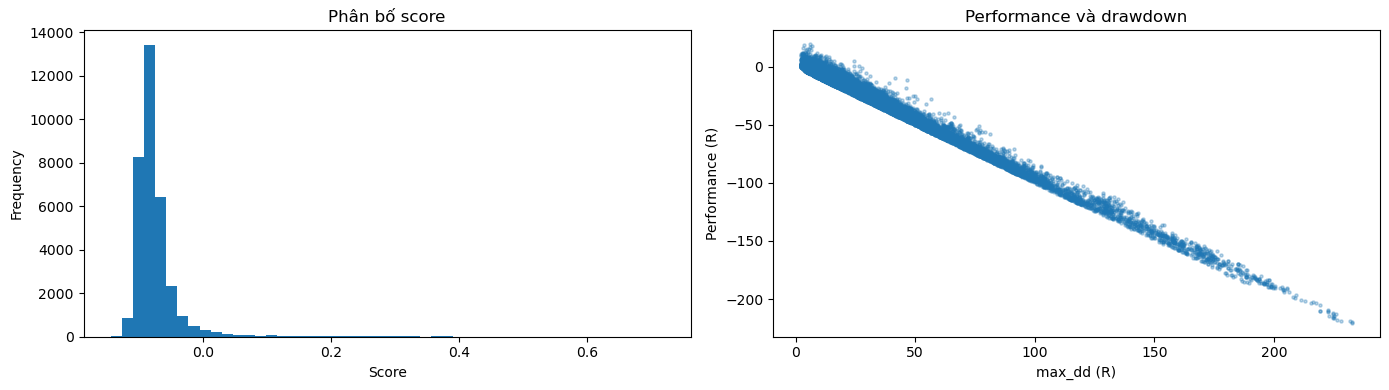

In [9]:
# Biểu đồ: phân bố score và hiệu quả theo drawdown
if ranked.empty:
    print("Không có score hợp lệ để vẽ")
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    ranked["score"].plot.hist(ax=axes[0], bins=50, title="Phân bố score")
    axes[0].set_xlabel("Score")
    axes[1].scatter(ranked["max_dd"], ranked["performance"], s=5, alpha=0.3)
    axes[1].set(xlabel="max_dd (R)", ylabel="Performance (R)", title="Performance và drawdown")
    plt.tight_layout()
    plt.show()

C:\Users\Legion\anaconda3\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))


Giai đoạn backtest: 2024-07-01 00:00:00 đến 2026-01-14 13:15:00
Tham số: {'boll_window': 96.0, 'boll_window_dev': 1.8, 'rsi_window': 3.0, 'rsi_threshold': 35.0, 'sl_multiplier': 0.5, 'tp_sl_ratio': 2.0, 'entry_mode': 2.0}


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio,entry_mode,performance,max_dd,avg_dd,...,ulcer_r,r_martin_monthly,r_sharpe_monthly,mtm_max_dd,avg_concurrent,number_of_trade,max_concurrent,skipped_entries,score,score_formula
backtest_trial,96,1.8,3,35,0.5,2.0,2,18.884693,3.39,0.93,...,1.423121,0.717969,0.421683,3.875987,0.085713,50,1,8,0.717969,r_martin_monthly


,số lệnh
outcome,
stop,23
take_profit,21
timeout,6


,entry_index,entry_timestamp,exit_index,close_timestamp,entry_price,risk,stop_loss,take_profit,tp_r,holding_bars,open_at_entry,outcome,gross_r,entry_fee,holding_fee,net_r
0,975,2024-07-11 03:45:00,1263,2024-07-14 03:45:00,25.317,1.020098,24.296902,27.357196,2.0,288,1,timeout,0.572494,0.024818,0.022336,0.525339
1,3361,2024-08-05 00:15:00,3363,2024-08-05 00:45:00,21.100,1.101179,19.998821,23.302358,2.0,2,1,stop,-1.000000,0.019161,0.000120,-1.019281
2,4328,2024-08-15 02:00:00,4391,2024-08-15 17:45:00,20.850,0.382336,20.467664,21.614673,2.0,63,1,stop,-1.000000,0.054533,0.010736,-1.065269
3,5820,2024-08-30 15:00:00,6008,2024-09-01 14:00:00,22.587,0.735334,21.851666,24.057669,2.0,188,1,stop,-1.000000,0.030717,0.018046,-1.048763
4,7493,2024-09-17 01:15:00,7545,2024-09-17 14:15:00,23.198,0.436026,22.761974,24.070051,2.0,52,1,take_profit,2.000000,0.053203,0.008646,1.938151
5,8326,2024-09-25 17:30:00,8384,2024-09-26 08:00:00,27.333,0.411033,26.921967,28.155065,2.0,58,1,take_profit,2.000000,0.066498,0.012053,1.921449
6,8595,2024-09-28 12:45:00,8672,2024-09-29 08:00:00,29.301,0.782210,28.518790,30.865420,2.0,77,1,stop,-1.000000,0.037459,0.009014,-1.046473
7,9002,2024-10-02 18:30:00,9004,2024-10-02 19:00:00,25.623,0.476430,25.146570,26.575860,2.0,2,1,stop,-1.000000,0.053781,0.000336,-1.054117
8,10303,2024-10-16 07:45:00,10591,2024-10-19 07:45:00,27.323,0.918293,26.404707,29.159586,2.0,288,1,timeout,0.784064,0.029754,0.026779,0.727531
9,12792,2024-11-11 06:00:00,12833,2024-11-11 16:15:00,31.114,0.944250,30.169750,33.002500,2.0,41,1,take_profit,2.000000,0.032951,0.004222,1.962827


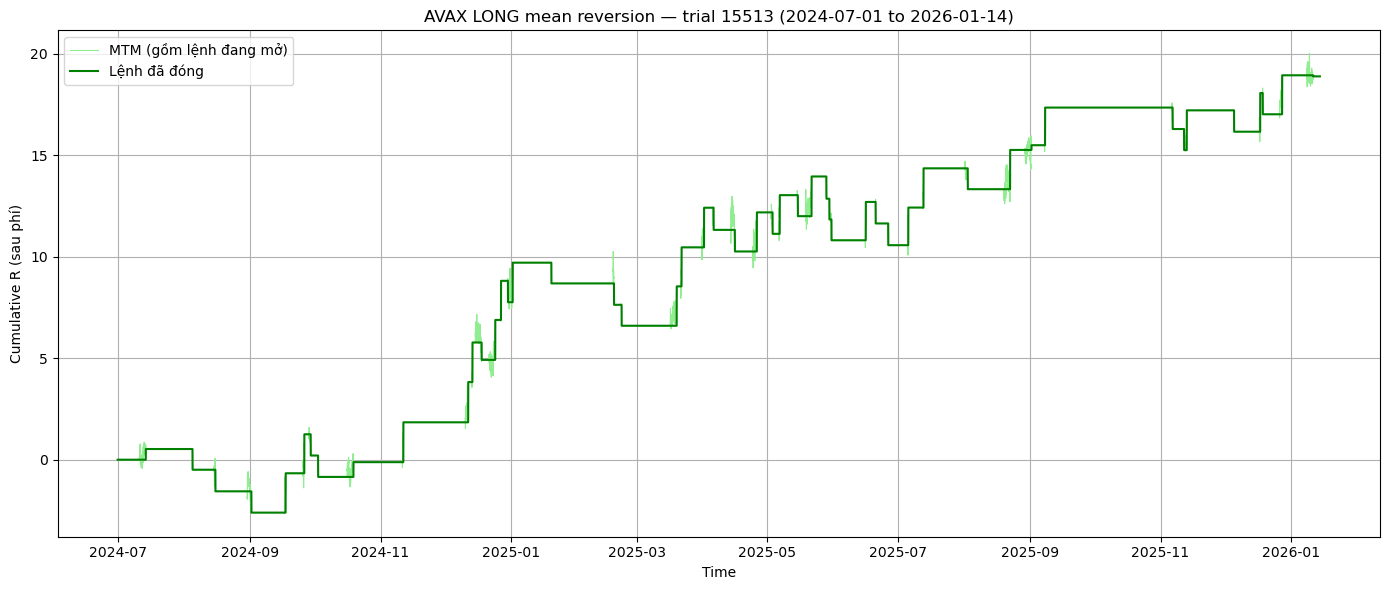

In [10]:
# Điền ID của trial trong bảng `result` (đếm từ 0), rồi chạy riêng ô này. None = bộ đứng đầu `ranked`.
TRIAL_ID = None
BACKTEST_START_DATE = None  # Ví dụ "2025-07-01"; None = ngày bắt đầu train
BACKTEST_END_DATE = None    # Ví dụ "2026-01-14"; None = ngày kết thúc train

if TRIAL_ID is None:
    if ranked.empty:
        raise ValueError("Bảng ranked rỗng; hãy điền TRIAL_ID")
    TRIAL_ID = int(ranked.index[0])
if TRIAL_ID not in result.index:
    raise KeyError(f"TRIAL_ID={TRIAL_ID} không có trong result.index")
params = grid.loc[TRIAL_ID].to_dict()
backtest_start = BACKTEST_START_DATE or start_date
backtest_end = BACKTEST_END_DATE or end_date
backtest_bars = (bars if BACKTEST_START_DATE is None and BACKTEST_END_DATE is None
                 else strategy.load_bars(csv_path, TIMEFRAME, backtest_start, backtest_end))

# GPU cho đúng một bộ tham số, và replay float64 liệt kê từng lệnh; hai bên phải khớp.
backtest_result, _ = strategy.run_gpu_grid(
    backtest_bars, grid.loc[[TRIAL_ID]].reset_index(drop=True), TIMEFRAME,
    max_holding_bars=MAX_HOLDING_BARS, fee_bars=FEE_BARS, score_formula=SCORE_FORMULA)
backtest_trial = backtest_result.iloc[0]
trades = strategy.cpu_trace(backtest_bars, params, TIMEFRAME, MAX_HOLDING_BARS, FEE_BARS)
replay = strategy.trade_metrics(backtest_bars, trades, TIMEFRAME, FEE_BARS)
if replay["number_of_trade"] != int(backtest_trial["number_of_trade"]):
    print(f"Lưu ý: GPU {int(backtest_trial['number_of_trade'])} lệnh, replay float64 {replay['number_of_trade']} "
          "(giá sát ngưỡng làm tròn fp32)")

print(f"Giai đoạn backtest: {backtest_bars['timestamp'].iloc[0]} đến {backtest_bars['timestamp'].iloc[-1]}")
print("Tham số:", params)
display(backtest_trial.to_frame(name="backtest_trial").T)
display(trades["outcome"].value_counts().to_frame("số lệnh"))
display(trades.head(20))

if trades.empty:
    print("Không có lệnh nào trong khoảng backtest")
else:
    equity = strategy.mtm_equity(backtest_bars, trades, TIMEFRAME, FEE_BARS)
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.plot(equity["timestamp"], equity["mtm_equity"], color="lightgreen", linewidth=0.8, label="MTM (gồm lệnh đang mở)")
    ax.plot(equity["timestamp"], equity["closed_equity"], color="green", label="Lệnh đã đóng")
    ax.set(xlabel="Time", ylabel="Cumulative R (sau phí)",
           title=f"AVAX LONG mean reversion — trial {TRIAL_ID} ({backtest_start} to {backtest_end})")
    ax.legend()
    ax.grid(True)
    fig.tight_layout()
    plt.show()

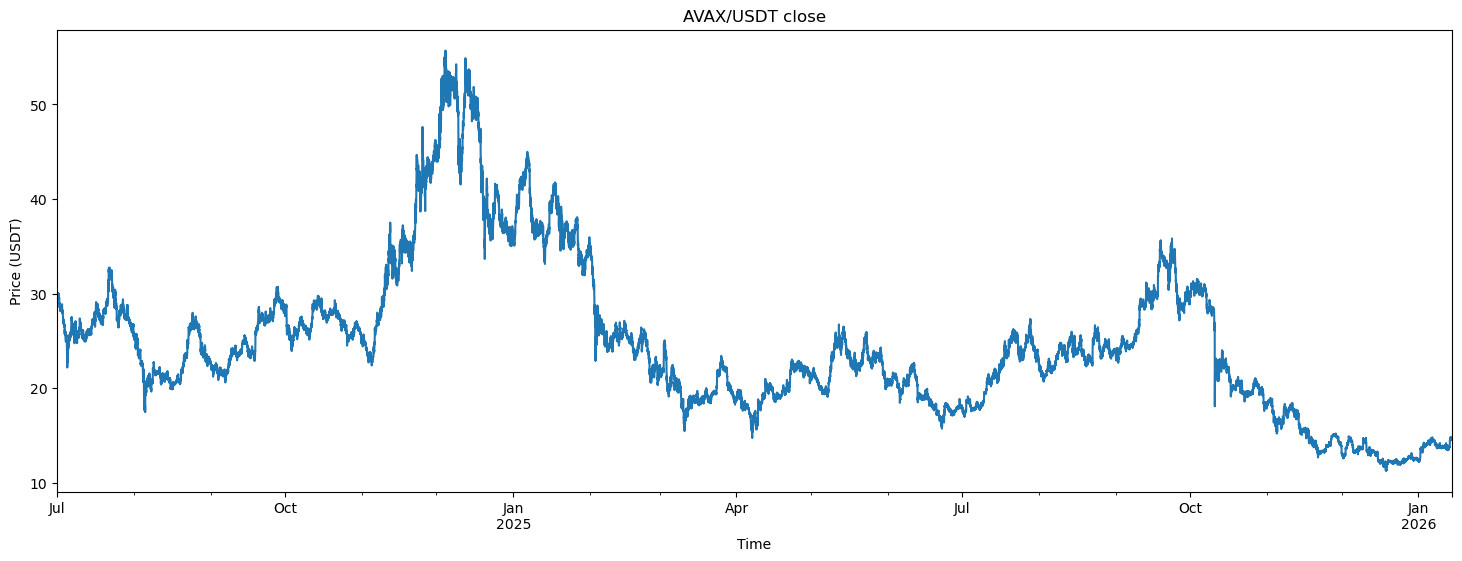

In [11]:
ax = backtest_bars.set_index("timestamp")["close"].plot(figsize=(18, 6))
ax.set(title="AVAX/USDT close", xlabel="Time", ylabel="Price (USDT)")
plt.show()